# Evaluation-set exploration: LibriSpeech and Earnings22

This notebook checks how `data/manifest_n300.csv` compares with the full LibriSpeech `test.clean` split and with a seeded simple random sample of the same size. It focuses on:

- audio duration, reference word count, and words per second;
- speaker representation and coverage of all 40 test-clean speakers;
- the duration-quantile thresholds used by the project's speaker-first, duration-balanced sampler.

The full split has only 2,620 utterances. Audio is **not decoded into waveforms**: the one-time metadata build reads FLAC headers to obtain durations, then stores a small derived cache at `data/librispeech_test_clean_metadata.csv`. Subsequent runs reuse that cache. The existing manifest and inference results are read-only.

In [1]:
from pathlib import Path
from io import BytesIO
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Work whether Jupyter starts in the repository root or in notebooks/.
candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (p for p in candidates if (p / 'data' / 'manifest_n300.csv').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Could not locate data/manifest_n300.csv. Start Jupyter from the project root or notebooks/.'
    )

MANIFEST_PATH = PROJECT_ROOT / 'data' / 'manifest_n300.csv'
METADATA_CACHE = PROJECT_ROOT / 'data' / 'librispeech_test_clean_metadata.csv'
SEED = 42

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')

print(f'Python: {sys.executable}')
print(f'Project root: {PROJECT_ROOT}')
print(f'Manifest: {MANIFEST_PATH.relative_to(PROJECT_ROOT)}')

Python: /Users/sheetallaad/Documents/InterviewPrep/Deepgram/asr-leaderboard-eval/.venv/bin/python
Project root: /Users/sheetallaad/Documents/InterviewPrep/Deepgram/asr-leaderboard-eval
Manifest: data/manifest_n300.csv


## Load full-split metadata without waveform decoding

The first run streams the official Hugging Face LibriSpeech test-clean split. `Audio(decode=False)` keeps each recording encoded; `soundfile.info` reads only the FLAC header needed for duration.

In [2]:
def _duration_from_encoded_audio(audio_record):
    """Return duration from a FLAC header without decoding a waveform."""
    import soundfile as sf

    audio_bytes = audio_record.get('bytes')
    audio_path = audio_record.get('path')
    if audio_bytes is not None:
        return float(sf.info(BytesIO(audio_bytes)).duration)
    if audio_path and Path(audio_path).exists():
        return float(sf.info(audio_path).duration)
    raise ValueError('Encoded audio had neither bytes nor a readable local path.')


def load_or_build_full_metadata(cache_path=METADATA_CACHE):
    required = {'sample_id', 'speaker_id', 'reference', 'duration_sec'}
    if cache_path.exists():
        cached = pd.read_csv(
            cache_path,
            dtype={'sample_id': 'string', 'speaker_id': 'string'},
        )
        missing = required.difference(cached.columns)
        if missing:
            raise ValueError(f'Metadata cache is missing columns: {sorted(missing)}')
        print(f'Reused metadata cache: {cache_path.relative_to(PROJECT_ROOT)}')
        return cached

    from datasets import Audio, load_dataset
    from tqdm import tqdm

    print('Building metadata cache once; this streams encoded test-clean audio but never decodes waveforms.')
    dataset = load_dataset(
        'openslr/librispeech_asr',
        'clean',
        split='test',
        streaming=True,
    ).cast_column('audio', Audio(decode=False))

    records = []
    for row in tqdm(dataset, desc='Reading FLAC headers', total=2620):
        records.append({
            'sample_id': str(row['id']),
            'speaker_id': str(row['speaker_id']),
            'reference': row['text'],
            'duration_sec': _duration_from_encoded_audio(row['audio']),
        })

    metadata = pd.DataFrame.from_records(records)
    metadata.to_csv(cache_path, index=False)
    print(f'Saved derived metadata cache: {cache_path.relative_to(PROJECT_ROOT)}')
    return metadata


full = load_or_build_full_metadata()
manifest = pd.read_csv(
    MANIFEST_PATH,
    dtype={'sample_id': 'string', 'speaker_id': 'string'},
)

print(f'Full split: {len(full):,} utterances, {full.speaker_id.nunique()} speakers')
print(f'Manifest:   {len(manifest):,} utterances, {manifest.speaker_id.nunique()} speakers')

Reused metadata cache: data/librispeech_test_clean_metadata.csv
Full split: 2,620 utterances, 40 speakers
Manifest:   300 utterances, 40 speakers


In [3]:
def add_features(frame):
    result = frame.copy()
    result['word_count'] = result['reference'].fillna('').str.split().str.len().astype('int64')
    result['words_per_second'] = result['word_count'] / result['duration_sec']
    return result


full = add_features(full)
manifest = add_features(manifest)

if not manifest.sample_id.is_unique:
    raise AssertionError('Manifest contains duplicate sample IDs.')
missing_ids = set(manifest.sample_id) - set(full.sample_id)
if missing_ids:
    raise AssertionError(f'{len(missing_ids)} manifest IDs were not found in test-clean.')

# A reproducible simple random baseline, sampled uniformly by utterance.
random_sample = full.sample(n=len(manifest), random_state=SEED, replace=False).copy()

datasets = {
    'Full test-clean': full,
    'Speaker-first + duration-balanced': manifest,
    'Simple random sample': random_sample,
}

pd.DataFrame({
    name: {
        'utterances': len(frame),
        'speakers': frame.speaker_id.nunique(),
        'hours': frame.duration_sec.sum() / 3600,
    }
    for name, frame in datasets.items()
}).T

,utterances,speakers,hours
Full test-clean,"2,620.000",40.000,5.403
Speaker-first + duration-balanced,300.000,40.000,0.622
Simple random sample,300.000,40.000,0.609


## Sampling thresholds and coverage

`src/sample_data.py` creates duration tertiles from the full split using `pd.qcut(q=3)`. The values below are the empirical 33⅓% and 66⅔% thresholds, creating the `short`, `medium`, and `long` labels.

In [4]:
quantile_levels = [0, 1/3, 2/3, 1]
duration_edges = full['duration_sec'].quantile(quantile_levels)
threshold_table = pd.DataFrame({
    'quantile': ['minimum', '33.3% (short / medium)', '66.7% (medium / long)', 'maximum'],
    'duration_sec': duration_edges.to_numpy(),
})
display(threshold_table.style.format({'duration_sec': '{:.3f}'}))

short_max = duration_edges.loc[1/3]
medium_max = duration_edges.loc[2/3]
full['duration_bucket'] = pd.cut(
    full.duration_sec,
    bins=[-np.inf, short_max, medium_max, np.inf],
    labels=['short', 'medium', 'long'],
    include_lowest=True,
)
for frame in (manifest, random_sample):
    frame['duration_bucket_recomputed'] = pd.cut(
        frame.duration_sec,
        bins=[-np.inf, short_max, medium_max, np.inf],
        labels=['short', 'medium', 'long'],
        include_lowest=True,
    )

if 'duration_bucket' in manifest.columns:
    disagreements = (
        manifest.duration_bucket.astype(str)
        != manifest.duration_bucket_recomputed.astype(str)
    ).sum()
    print(f'Manifest bucket labels reproduced: {disagreements == 0} ({disagreements} disagreements)')

,quantile,duration_sec
0,minimum,1.285
1,33.3% (short / medium),4.315
2,66.7% (medium / long),7.920
3,maximum,34.955


Manifest bucket labels reproduced: True (0 disagreements)


In [5]:
speaker_universe = set(full.speaker_id)
coverage_rows = []
for name, frame in datasets.items():
    represented = set(frame.speaker_id)
    coverage_rows.append({
        'dataset': name,
        'speakers represented': len(represented),
        'coverage': len(represented) / len(speaker_universe),
        'missing speakers': ', '.join(sorted(speaker_universe - represented)) or 'None',
        'min utterances / represented speaker': int(frame.groupby('speaker_id').size().min()),
        'max utterances / represented speaker': int(frame.groupby('speaker_id').size().max()),
    })
coverage = pd.DataFrame(coverage_rows).set_index('dataset')
display(coverage.style.format({'coverage': '{:.1%}'}))

assert len(speaker_universe) == 40, f'Expected 40 test-clean speakers, found {len(speaker_universe)}.'
assert manifest.speaker_id.nunique() == 40, 'The manifest does not cover all 40 speakers.'
print('✓ The speaker-first sample covers all 40 test-clean speakers.')

,speakers represented,coverage,missing speakers,min utterances / represented speaker,max utterances / represented speaker
dataset,,,,,
Full test-clean,40,100.0%,None,32,108
Speaker-first + duration-balanced,40,100.0%,None,3,16
Simple random sample,40,100.0%,None,4,16


✓ The speaker-first sample covers all 40 test-clean speakers.


## Distribution summaries

In [6]:
metrics = ['duration_sec', 'word_count', 'words_per_second']
metric_labels = {
    'duration_sec': 'Duration (seconds)',
    'word_count': 'Reference word count',
    'words_per_second': 'Words per second',
}
summary_parts = []
for name, frame in datasets.items():
    part = frame[metrics].describe(percentiles=[0.25, 0.5, 0.75]).T
    part.insert(0, 'dataset', name)
    part.index.name = 'metric'
    summary_parts.append(part.reset_index())
summary = pd.concat(summary_parts, ignore_index=True).set_index(['metric', 'dataset'])
display(summary[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']])

,,count,mean,std,min,25%,50%,75%,max
metric,dataset,,,,,,,,
duration_sec,Full test-clean,"2,620.000",7.425,5.154,1.285,3.679,5.790,9.601,34.955
word_count,Full test-clean,"2,620.000",20.067,13.726,1.000,10.000,16.500,27.000,96.000
words_per_second,Full test-clean,"2,620.000",2.721,0.592,0.552,2.345,2.718,3.107,4.604
duration_sec,Speaker-first + duration-balanced,300.000,7.470,4.993,1.485,3.715,6.285,9.595,33.910
word_count,Speaker-first + duration-balanced,300.000,20.303,13.840,2.000,10.000,17.000,26.000,96.000
words_per_second,Speaker-first + duration-balanced,300.000,2.714,0.587,0.920,2.343,2.717,3.089,4.374
duration_sec,Simple random sample,300.000,7.313,5.275,1.795,3.359,5.590,9.521,30.615
word_count,Simple random sample,300.000,19.567,13.767,2.000,9.000,16.000,27.000,83.000
words_per_second,Simple random sample,300.000,2.693,0.611,0.647,2.352,2.723,3.076,4.274


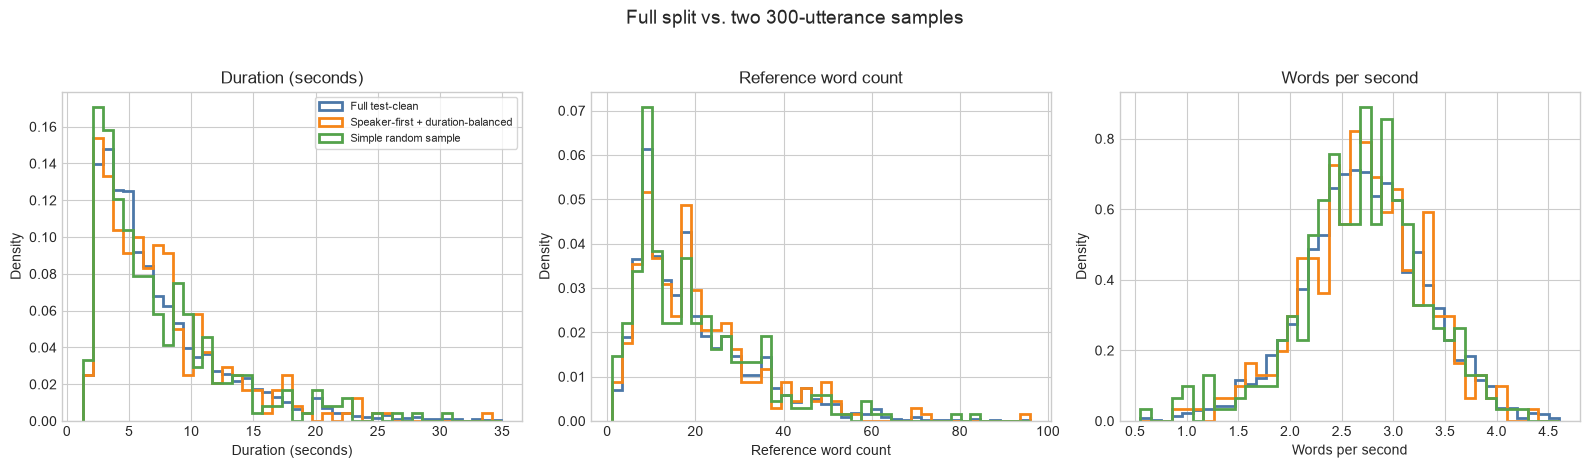

In [7]:
colors = {
    'Full test-clean': '#4C78A8',
    'Speaker-first + duration-balanced': '#F58518',
    'Simple random sample': '#54A24B',
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric in zip(axes, metrics):
    combined = pd.concat([frame[metric] for frame in datasets.values()], ignore_index=True)
    bins = np.histogram_bin_edges(combined, bins='fd')
    if len(bins) > 45:
        bins = np.linspace(combined.min(), combined.max(), 46)
    for name, frame in datasets.items():
        ax.hist(
            frame[metric], bins=bins, density=True, histtype='step', linewidth=2,
            color=colors[name], label=name,
        )
    ax.set_title(metric_labels[metric])
    ax.set_xlabel(metric_labels[metric])
    ax.set_ylabel('Density')
axes[0].legend(frameon=True, fontsize=8)
fig.suptitle('Full split vs. two 300-utterance samples', fontsize=14, y=1.03)
fig.tight_layout()
plt.show()

,short,medium,long
Full test-clean,874,874,872
Speaker-first + duration-balanced,96,103,101
Simple random sample,111,85,104


,short,medium,long
Full test-clean,33.4%,33.4%,33.3%
Speaker-first + duration-balanced,32.0%,34.3%,33.7%
Simple random sample,37.0%,28.3%,34.7%


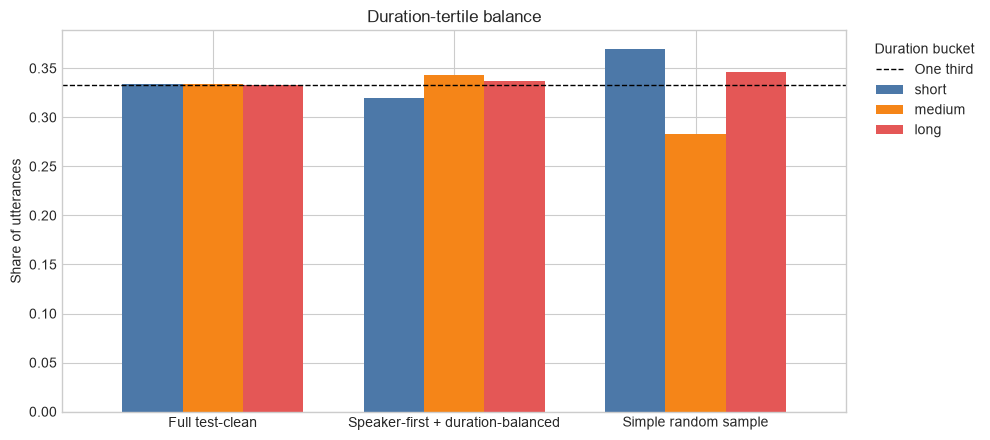

In [8]:
bucket_order = ['short', 'medium', 'long']
bucket_counts = pd.DataFrame({
    'Full test-clean': full.duration_bucket.value_counts().reindex(bucket_order),
    'Speaker-first + duration-balanced': manifest.duration_bucket_recomputed.value_counts().reindex(bucket_order),
    'Simple random sample': random_sample.duration_bucket_recomputed.value_counts().reindex(bucket_order),
})
bucket_shares = bucket_counts.div(bucket_counts.sum(axis=0), axis=1)
display(bucket_counts.T.style.set_caption('Utterance counts by full-split duration tertile'))
display(bucket_shares.T.style.format('{:.1%}').set_caption('Share by full-split duration tertile'))

ax = bucket_shares.T.plot(
    kind='bar', figsize=(10, 4.5), color=['#4C78A8', '#F58518', '#E45756'], width=0.75
)
ax.axhline(1/3, color='black', linestyle='--', linewidth=1, label='One third')
ax.set_ylabel('Share of utterances')
ax.set_xlabel('')
ax.set_title('Duration-tertile balance')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Duration bucket', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

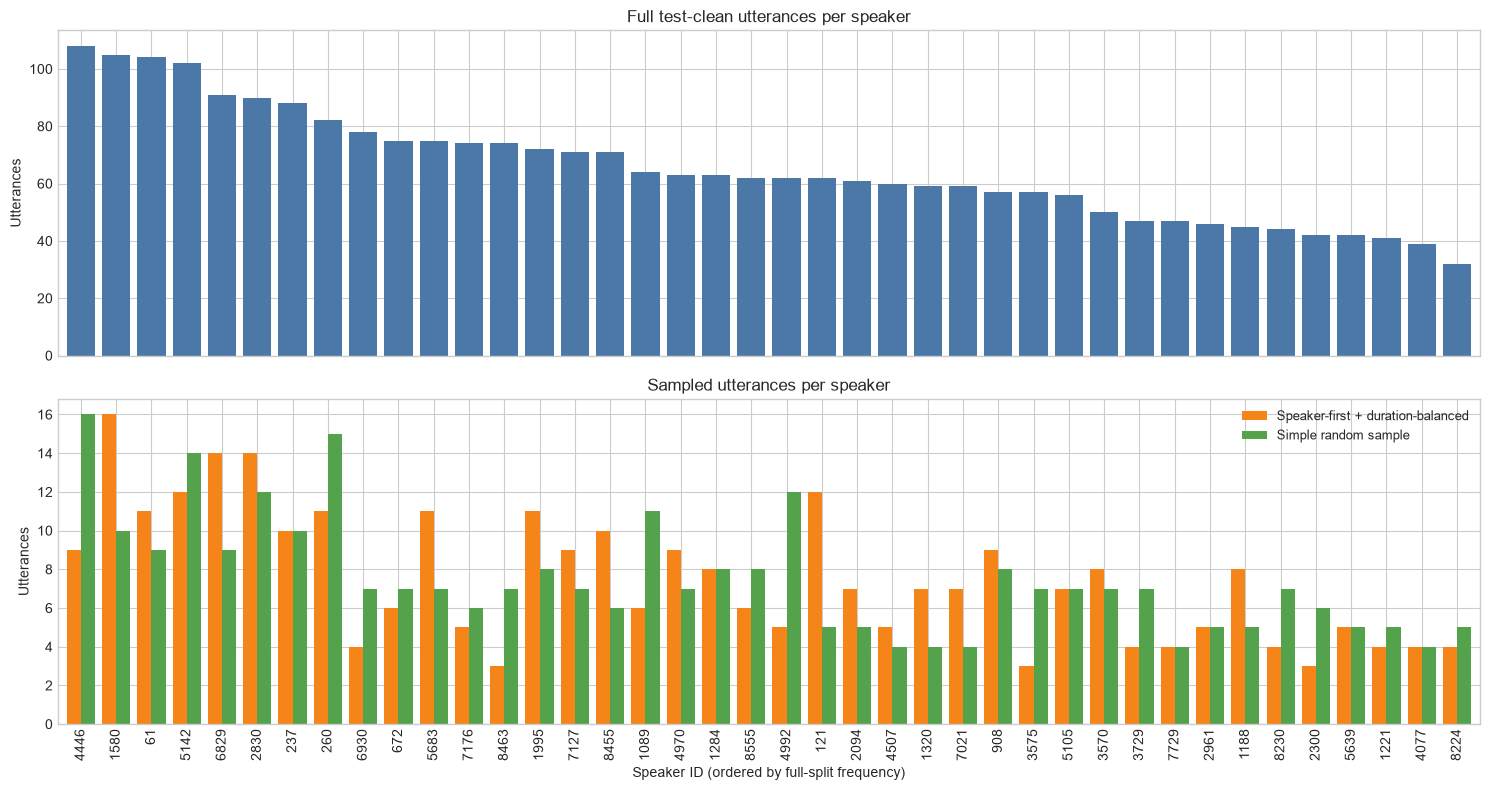

In [9]:
speaker_counts = pd.DataFrame({
    name: frame.groupby('speaker_id').size()
    for name, frame in datasets.items()
}).fillna(0).astype(int)
speaker_counts = speaker_counts.sort_values('Full test-clean', ascending=False)

fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True, height_ratios=[1, 1])
speaker_counts['Full test-clean'].plot(kind='bar', ax=axes[0], color=colors['Full test-clean'], width=0.8)
axes[0].set_title('Full test-clean utterances per speaker')
axes[0].set_ylabel('Utterances')

speaker_counts[['Speaker-first + duration-balanced', 'Simple random sample']].plot(
    kind='bar', ax=axes[1],
    color=[colors['Speaker-first + duration-balanced'], colors['Simple random sample']],
    width=0.8,
)
axes[1].set_title('Sampled utterances per speaker')
axes[1].set_ylabel('Utterances')
axes[1].set_xlabel('Speaker ID (ordered by full-split frequency)')
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

## Quantify representativeness

For each numeric feature, the table reports the sample-to-full difference in mean and median, plus the two-sample Kolmogorov–Smirnov statistic. Smaller absolute differences and smaller KS values mean closer agreement with the full empirical distribution. These are descriptive diagnostics, not hypothesis tests: both samples are drawn from the full split.

In [10]:
def ks_distance(a, b):
    """Two-sample empirical CDF distance, implemented with NumPy only."""
    a = np.sort(np.asarray(a, dtype=float))
    b = np.sort(np.asarray(b, dtype=float))
    points = np.sort(np.concatenate([a, b]))
    cdf_a = np.searchsorted(a, points, side='right') / len(a)
    cdf_b = np.searchsorted(b, points, side='right') / len(b)
    return float(np.max(np.abs(cdf_a - cdf_b)))


comparison_rows = []
for sample_name in ['Speaker-first + duration-balanced', 'Simple random sample']:
    sample = datasets[sample_name]
    for metric in metrics:
        comparison_rows.append({
            'sample': sample_name,
            'metric': metric_labels[metric],
            'mean difference': sample[metric].mean() - full[metric].mean(),
            'median difference': sample[metric].median() - full[metric].median(),
            'standardized mean difference': (sample[metric].mean() - full[metric].mean()) / full[metric].std(ddof=1),
            'KS distance': ks_distance(sample[metric], full[metric]),
        })
diagnostics = pd.DataFrame(comparison_rows).set_index(['sample', 'metric'])
display(diagnostics.style.format('{:+.3f}'))

In [15]:
# Generate an interpretation from the computed results rather than hard-coding conclusions.
balanced_speakers = manifest.speaker_id.nunique()
random_speakers = random_sample.speaker_id.nunique()
balanced_bucket_gap = (bucket_shares['Speaker-first + duration-balanced'] - 1/3).abs().max()
random_bucket_gap = (bucket_shares['Simple random sample'] - 1/3).abs().max()

closer = {}
for metric in metrics:
    b = diagnostics.loc[('Speaker-first + duration-balanced', metric_labels[metric]), 'KS distance']
    r = diagnostics.loc[('Simple random sample', metric_labels[metric]), 'KS distance']
    closer[metric_labels[metric]] = 'balanced sample' if b < r else ('random sample' if r < b else 'tie')

coverage_sentence = (
    f'Both samples happen to cover all 40 speakers in this seeded comparison, but only the speaker-first design guarantees that coverage.'
    if random_speakers == 40
    else f'The speaker-first sample covers all 40 speakers; the random baseline covers {random_speakers}/40 and misses {40-random_speakers}.'
)
metric_lines = '\n'.join(
    f'  - **{label}:** lower KS distance for the {winner}.'
    for label, winner in closer.items()
)

display(Markdown(f'''
### Interpretation

- **Speaker coverage:** {coverage_sentence}
- **Duration balance:** the designed sample's largest departure from an exact one-third allocation is {balanced_bucket_gap:.1%}, versus {random_bucket_gap:.1%} for this random draw. The designed sample is therefore more controlled across short, medium, and long utterances.
- **What the design does not directly stratify:** The sample was balanced by speaker and audio duration, not by transcript length or speaking rate. Those characteristics may still be reasonably representative because they are related to duration and speaker, but the sampling process did not guarantee it.
- **How well the 300-recording sample represents the full dataset:**
{metric_lines}

The speaker-first, duration-balanced sample trades purely random selection for guaranteed speaker inclusion and controlled duration coverage. That is useful for an ASR benchmark where missing a speaker or under-representing long clips could hide failure modes. It is not automatically closer to the full split on every feature, and its aggregate scores should be described as estimates for this designed evaluation set, not as an unqualified simple-random estimate of the full corpus. The analysis below compares the designed sample with 1,000 random samples, rather than relying on a potentially unrepresentative comparison with a single random sample.
'''))


### Interpretation

- **Speaker coverage:** Both samples happen to cover all 40 speakers in this seeded comparison, but only the speaker-first design guarantees that coverage.
- **Duration balance:** the designed sample's largest departure from an exact one-third allocation is 1.3%, versus 5.0% for this random draw. The designed sample is therefore more controlled across short, medium, and long utterances.
- **What the design does not directly stratify:** The sample was balanced by speaker and audio duration, not by transcript length or speaking rate. Those characteristics may still be reasonably representative because they are related to duration and speaker, but the sampling process did not guarantee it.
- **How well the 300-recording sample represents the full dataset:**
  - **Duration (seconds):** lower KS distance for the random sample.
  - **Reference word count:** lower KS distance for the balanced sample.
  - **Words per second:** lower KS distance for the balanced sample.

The speaker-first, duration-balanced sample trades purely random selection for guaranteed speaker inclusion and controlled duration coverage. That is useful for an ASR benchmark where missing a speaker or under-representing long clips could hide failure modes. It is not automatically closer to the full split on every feature, and its aggregate scores should be described as estimates for this designed evaluation set, not as an unqualified simple-random estimate of the full corpus. The analysis below compares the designed sample with 1,000 random samples, rather than relying on a potentially unrepresentative comparison with a single random sample.


## Repeated random-sample benchmark

A single random draw can be unusually good or bad. The following simulation draws 1,000 uniform 300-utterance samples from the full split and compares their speaker coverage and distribution distances with the designed sample. The percentile is the share of random draws with a value no larger than the designed sample: a high percentile is desirable for speaker coverage, while a low percentile is desirable for distance and imbalance diagnostics.

diagnostic,designed sample,random median,random 5th percentile,random 95th percentile,% random draws ≤ designed value
speakers represented,40.000,40.000,39.000,40.000,100.0%
maximum duration-bucket imbalance,0.013,0.027,0.007,0.060,14.8%
duration_sec KS,0.054,0.044,0.028,0.073,72.5%
word_count KS,0.037,0.040,0.023,0.067,42.4%
words_per_second KS,0.026,0.044,0.028,0.075,2.8%


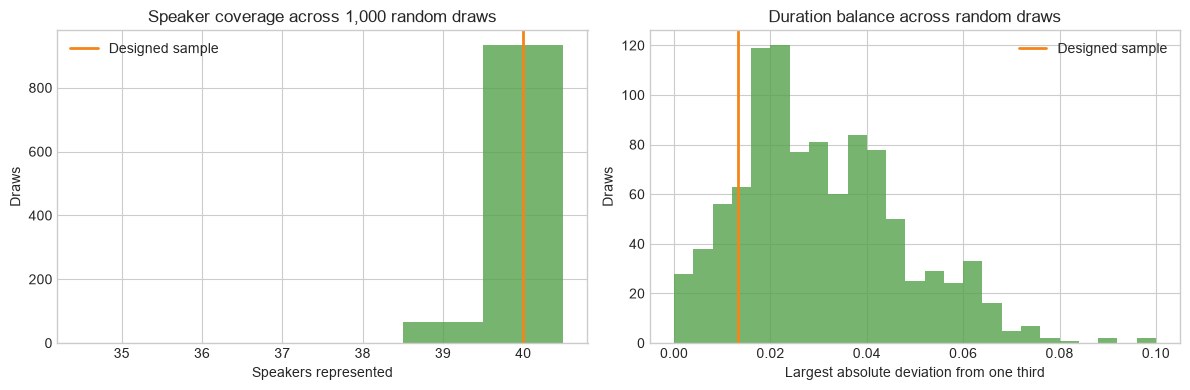

In [12]:
simulation_rng = np.random.default_rng(SEED)
simulation_rows = []
for draw in range(1_000):
    positions = simulation_rng.choice(len(full), size=len(manifest), replace=False)
    candidate = full.iloc[positions]
    bucket_share = candidate['duration_bucket'].value_counts(normalize=True).reindex(bucket_order, fill_value=0)
    simulation_rows.append({
        'speakers represented': candidate['speaker_id'].nunique(),
        'maximum duration-bucket imbalance': (bucket_share - 1 / 3).abs().max(),
        **{f'{metric} KS': ks_distance(candidate[metric], full[metric]) for metric in metrics},
    })
random_draws = pd.DataFrame(simulation_rows)
designed_values = {
    'speakers represented': manifest['speaker_id'].nunique(),
    'maximum duration-bucket imbalance': balanced_bucket_gap,
    **{f'{metric} KS': diagnostics.loc[('Speaker-first + duration-balanced', metric_labels[metric]), 'KS distance'] for metric in metrics},
}
comparison = []
for diagnostic, designed_value in designed_values.items():
    random_values = random_draws[diagnostic]
    if diagnostic == 'speakers represented':
        percentile = (random_values <= designed_value).mean()
    else:
        percentile = (random_values <= designed_value).mean()
    comparison.append({
        'diagnostic': diagnostic,
        'designed sample': designed_value,
        'random median': random_values.median(),
        'random 5th percentile': random_values.quantile(0.05),
        'random 95th percentile': random_values.quantile(0.95),
        '% random draws ≤ designed value': percentile,
    })
random_comparison = pd.DataFrame(comparison)
display(random_comparison.style.hide(axis='index').format({
    'designed sample': '{:.3f}', 'random median': '{:.3f}',
    'random 5th percentile': '{:.3f}', 'random 95th percentile': '{:.3f}',
    '% random draws ≤ designed value': '{:.1%}',
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(random_draws['speakers represented'], bins=np.arange(34.5, 41.5, 1), color='#54A24B', alpha=0.8)
axes[0].axvline(designed_values['speakers represented'], color='#F58518', linewidth=2, label='Designed sample')
axes[0].set(title='Speaker coverage across 1,000 random draws', xlabel='Speakers represented', ylabel='Draws')
axes[0].legend()
axes[1].hist(random_draws['maximum duration-bucket imbalance'], bins=25, color='#54A24B', alpha=0.8)
axes[1].axvline(designed_values['maximum duration-bucket imbalance'], color='#F58518', linewidth=2, label='Designed sample')
axes[1].set(title='Duration balance across random draws', xlabel='Largest absolute deviation from one third', ylabel='Draws')
axes[1].legend()
plt.tight_layout()
plt.show()

## Is 300 a reasonable evaluation size?

For an initial local comparison, 300 recordings was reasonable: it covered all 40 speakers, included balanced duration groups, and represented 11.5% of the full test set. It also matched the full dataset’s speaking-rate distribution better than 97.2% of random samples, although its overall duration distribution was worse than most random samples.

The sample identified the broad model ranking, but it was not large enough to resolve the small difference between Small and Medium. The full 2,620-recording run was therefore used for the final results.

## Earnings22: full-versus-sampled metadata

The out-of-domain experiment uses 300 of the 2,741 public Earnings22 segments. The sample is allocated proportionally within **source-call × duration-tertile** strata. This section tests whether it retains the full set's duration, reference word-count, words-per-second, and source-call distributions. It reads cached text metadata created by `src.sample_earnings22` and never decodes audio.

**Important:** Earnings22 identifies which call each recording came from, but not who is speaking. Therefore, call coverage shows that the sample includes all source calls, it does not show that individual speakers are equally represented.

In [17]:
EARNINGS_METADATA_PATH = PROJECT_ROOT / 'data' / 'earnings22_metadata.csv'
EARNINGS_MANIFEST_PATH = PROJECT_ROOT / 'data' / 'earnings22_manifest_n300.csv'
missing_earnings_files = [
    path for path in [EARNINGS_METADATA_PATH, EARNINGS_MANIFEST_PATH]
    if not path.exists()
]
if missing_earnings_files:
    raise FileNotFoundError(
        'Missing Earnings22 metadata. From the project root, run: '
        '.venv/bin/python -m src.sample_earnings22 --n 300 --seed 42'
    )

earnings_full = pd.read_csv(
    EARNINGS_METADATA_PATH,
    dtype={'sample_id': str, 'source_call_id': str},
)
earnings_sample = pd.read_csv(
    EARNINGS_MANIFEST_PATH,
    dtype={'sample_id': str, 'source_call_id': str},
)

def add_earnings_features(frame):
    result = frame.copy()
    result['reference_word_count'] = (
        result['reference'].fillna('').str.split().str.len().astype('int64')
    )
    result['words_per_second'] = (
        result['reference_word_count'] / result['duration_sec']
    )
    return result

earnings_full = add_earnings_features(earnings_full)
earnings_sample = add_earnings_features(earnings_sample)

if not earnings_full.sample_id.is_unique or not earnings_sample.sample_id.is_unique:
    raise AssertionError('Earnings22 IDs must be unique.')
if not set(earnings_sample.sample_id).issubset(set(earnings_full.sample_id)):
    raise AssertionError('The Earnings22 manifest is not a subset of the cached metadata.')
reference_lookup = earnings_full.set_index('sample_id')['reference']
if not earnings_sample.set_index('sample_id')['reference'].equals(
    reference_lookup.loc[earnings_sample.sample_id]
):
    raise AssertionError('Earnings22 references differ between manifest and metadata cache.')

display(pd.DataFrame([
    {
        'dataset': 'Full Earnings22',
        'segments': len(earnings_full),
        'audio hours': earnings_full.duration_sec.sum() / 3600,
        'source calls': earnings_full.source_call_id.nunique(),
    },
    {
        'dataset': 'Stratified sample',
        'segments': len(earnings_sample),
        'audio hours': earnings_sample.duration_sec.sum() / 3600,
        'source calls': earnings_sample.source_call_id.nunique(),
    },
]).style.hide(axis='index').format({'audio hours': '{:.2f}'}))

dataset,segments,audio hours,source calls
Full Earnings22,2741,5.43,6
Stratified sample,300,0.59,6


### Full-versus-sample distributions and quantiles

Word count is the number of words in the reference transcript. Words per second divides that count by the recording length to estimate speaking rate. Both describe the dataset, not model accuracy.

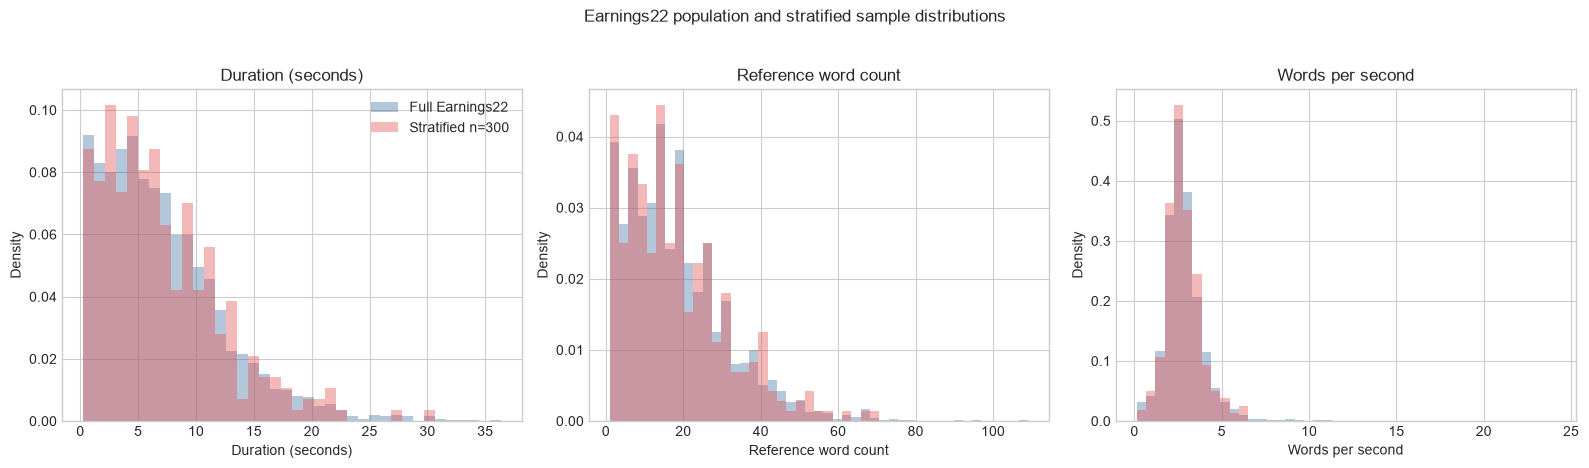

In [18]:
earnings_metrics = {
    'duration_sec': 'Duration (seconds)',
    'reference_word_count': 'Reference word count',
    'words_per_second': 'Words per second',
}
earnings_colors = {'Full Earnings22': '#4C78A8', 'Stratified n=300': '#E45756'}
earnings_frames = {
    'Full Earnings22': earnings_full,
    'Stratified n=300': earnings_sample,
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (metric, label) in zip(axes, earnings_metrics.items()):
    bins = np.histogram_bin_edges(earnings_full[metric], bins='fd')
    if len(bins) > 45:
        bins = np.linspace(earnings_full[metric].min(), earnings_full[metric].max(), 46)
    for name, frame in earnings_frames.items():
        ax.hist(
            frame[metric], bins=bins, density=True, alpha=0.42,
            color=earnings_colors[name], label=name,
        )
    ax.set(title=label, xlabel=label, ylabel='Density')
axes[0].legend()
fig.suptitle('Earnings22 population and stratified sample distributions', y=1.03)
plt.tight_layout()
plt.show()

In [19]:
earnings_quantiles = [0, 0.10, 0.25, 0.50, 0.75, 0.90, 1]
earnings_quantile_rows = []
for metric, label in earnings_metrics.items():
    full_values = earnings_full[metric].quantile(earnings_quantiles)
    sample_values = earnings_sample[metric].quantile(earnings_quantiles)
    for q in earnings_quantiles:
        earnings_quantile_rows.append({
            'metric': label,
            'quantile': f'{q:.0%}',
            'full': full_values.loc[q],
            'sample': sample_values.loc[q],
            'sample − full': sample_values.loc[q] - full_values.loc[q],
        })
earnings_quantile_table = pd.DataFrame(earnings_quantile_rows)
display(earnings_quantile_table.style.hide(axis='index').format({
    'full': '{:.2f}', 'sample': '{:.2f}', 'sample − full': '{:+.2f}',
}))

metric,quantile,full,sample,sample − full
Duration (seconds),0%,0.22,0.32,+0.10
Duration (seconds),10%,1.34,1.51,+0.17
Duration (seconds),25%,3.14,3.06,-0.08
Duration (seconds),50%,6.14,6.03,-0.11
Duration (seconds),75%,9.86,9.95,+0.08
Duration (seconds),90%,14.06,13.53,-0.53
Duration (seconds),100%,36.36,30.46,-5.90
Reference word count,0%,1.00,1.00,+0.00
Reference word count,10%,4.00,3.00,-1.00
Reference word count,25%,9.00,8.00,-1.00


### Source-call proportions

The sample includes recordings from each call in roughly the same proportions as the full dataset. Calls with more recordings therefore receive more sample rows. A call may contain multiple speakers, so this does not guarantee balanced speaker representation.

source_call_id,full,sample,difference_pp
4432298,12.84%,12.67%,-0.18
4450488,18.57%,18.33%,-0.24
4470290,6.53%,6.67%,+0.14
4479741,17.29%,17.33%,+0.04
4483338,22.62%,22.67%,+0.05
4485244,22.15%,22.33%,+0.19


**Maximum absolute source-call share difference: 0.24 percentage points.**

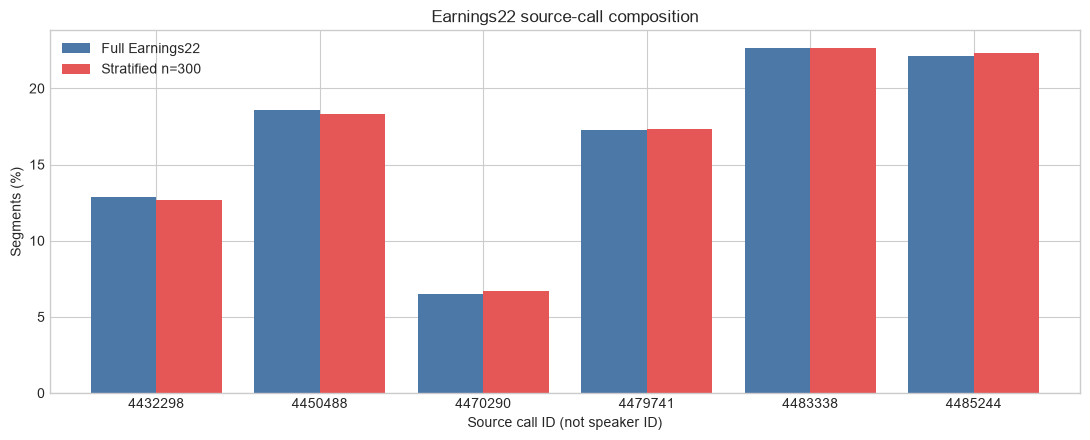

In [20]:
earnings_call_proportions = pd.DataFrame({
    'full': earnings_full.source_call_id.value_counts(normalize=True),
    'sample': earnings_sample.source_call_id.value_counts(normalize=True),
}).fillna(0).sort_index()
earnings_call_proportions['difference_pp'] = (
    100 * (earnings_call_proportions['sample'] - earnings_call_proportions['full'])
)
max_call_share_difference_pp = earnings_call_proportions.difference_pp.abs().max()

display(earnings_call_proportions.reset_index(names='source_call_id').style.hide(axis='index').format({
    'full': '{:.2%}', 'sample': '{:.2%}', 'difference_pp': '{:+.2f}',
}))
display(Markdown(
    f'**Maximum absolute source-call share difference: {max_call_share_difference_pp:.2f} percentage points.**'
))

ax = (100 * earnings_call_proportions[['full', 'sample']]).plot(
    kind='bar', figsize=(11, 4.5), color=['#4C78A8', '#E45756'], width=0.8,
)
ax.set(
    title='Earnings22 source-call composition',
    xlabel='Source call ID (not speaker ID)',
    ylabel='Segments (%)',
)
ax.legend(['Full Earnings22', 'Stratified n=300'])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
earnings_diagnostic_rows = []
for metric, label in earnings_metrics.items():
    full_values = earnings_full[metric]
    sample_values = earnings_sample[metric]
    earnings_diagnostic_rows.append({
        'metric': label,
        'full mean': full_values.mean(),
        'sample mean': sample_values.mean(),
        'mean difference (%)': 100 * (sample_values.mean() / full_values.mean() - 1),
        'full median': full_values.median(),
        'sample median': sample_values.median(),
        'KS distance': ks_distance(sample_values, full_values),
    })
earnings_diagnostics = pd.DataFrame(earnings_diagnostic_rows)
display(earnings_diagnostics.style.hide(axis='index').format({
    'full mean': '{:.2f}', 'sample mean': '{:.2f}',
    'mean difference (%)': '{:+.2f}%',
    'full median': '{:.2f}', 'sample median': '{:.2f}',
    'KS distance': '{:.3f}',
}))

duration_mean_difference = earnings_diagnostics.loc[
    earnings_diagnostics.metric == 'Duration (seconds)', 'mean difference (%)'
].iloc[0]
largest_ks_row = earnings_diagnostics.loc[earnings_diagnostics['KS distance'].idxmax()]
display(Markdown(
    f'**Interpretation.** The sample includes {len(earnings_sample):,} of '
    f'{len(earnings_full):,} recordings '
    f'({len(earnings_sample) / len(earnings_full):.1%}) and all '
    f'{earnings_full.source_call_id.nunique()} source calls. Its recording lengths, '
    f'speaking rates, word counts, and mix of calls are close to the full dataset. '
    f'The largest difference in call share is '
    f'{max_call_share_difference_pp:.2f} percentage points, and the largest KS '
    f'distance is {largest_ks_row["KS distance"]:.3f} for '
    f'{largest_ks_row.metric.lower()}. This sample is useful for checking whether '
    f'model performance changes on Earnings22, but it does not replace an evaluation '
    f'of all {len(earnings_full):,} recordings. Earnings22 also does not provide '
    f'reliable speaker IDs, so performance across individual speakers cannot be tested.'
))

metric,full mean,sample mean,mean difference (%),full median,sample median,KS distance
Duration (seconds),7.13,7.10,-0.45%,6.14,6.03,0.030
Reference word count,18.28,18.22,-0.31%,16.00,16.00,0.019
Words per second,2.86,2.79,-2.45%,2.67,2.62,0.038


**Interpretation.** The sample includes 300 of 2,741 recordings (10.9%) and all 6 source calls. Its recording lengths, speaking rates, word counts, and mix of calls are close to the full dataset. The largest difference in call share is 0.24 percentage points, and the largest KS distance is 0.038 for words per second. This sample is useful for checking whether model performance changes on Earnings22, but it does not replace an evaluation of all 2,741 recordings. Earnings22 also does not provide reliable speaker IDs, so performance across individual speakers cannot be tested.

## Reproducibility notes

- Run this notebook with the project's `.venv` Python interpreter.
- The derived full-split metadata caches are `data/librispeech_test_clean_metadata.csv` and `data/earnings22_metadata.csv`
- Rebuild the Earnings22 metadata and fixed sample with `.venv/bin/python -m src.sample_earnings22 --n 300 --seed 42`.
- The random comparison uses `random_state=42`, matching the manifest sampling seed.